# Étude progressive des réseaux de neurones sur le jeu de données HAR

**Projet de Deep Learning, M2 MALIA, 2026-2027** (enseignant : Walid Bechkit)
**Auteur :** Martine Ouedraogo
**Ce notebook :** Version 1, réseau à une seule couche cachée (baseline)

## Objectif du projet

Je veux reconnaître l'activité d'une personne à partir des mesures des capteurs de son smartphone (accéléromètre et gyroscope). Il y a 6 activités : WALKING, WALKING_UPSTAIRS, WALKING_DOWNSTAIRS, SITTING, STANDING et LAYING.

Je pars d'une référence simple (une régression logistique), puis je construis des réseaux de neurones de plus en plus complexes pour voir ce qu'apportent la taille du réseau, les fonctions d'activation, les optimiseurs et la régularisation. Mon but est de comprendre et de justifier mes choix, pas d'obtenir la meilleure accuracy.

Les règles que je suis (demandées dans l'énoncé) :
- tous les choix se font sur un ensemble de validation composé de volontaires entiers ;
- les comparaisons importantes sont répétées avec plusieurs graines (moyenne ± écart-type) ;
- le jeu de test n'est utilisé qu'une seule fois, à la fin ;
- les graines aléatoires sont fixées pour que les résultats soient reproductibles.

## Plan du notebook

La numérotation est celle de l'énoncé : une **Partie** (1, 2, 3…), puis ses questions (1.1, 1.2…), puis mes étapes (1.2.1, 1.2.2…).

| Partie | Sujet | Dans ce notebook (Version 1) | État |
|---|---|---|---|
| 1 | Jeu de données : exploration, validation, référence | 1.1 à 1.4 | fait |
| 2 | Première architecture (une couche cachée) | 2.1 à 2.3 | à faire |
| 3 | Extension de l'architecture | 3.1 (taille de la couche cachée) | à faire |
| 5 | Visualisation et analyse des performances | 5.1 et 5.2 | à faire |

Les parties qui demandent un réseau plus profond ou davantage d'outils (3.2, 4 régularisation, 6 t-SNE/UMAP, 7 bonus) iront dans le notebook Version 2.

**Ordre des cellules du notebook, selon la structure de code imposée par l'énoncé (8.1) :**

| Structure 8.1 | Où la trouver |
|---|---|
| 1. Imports | Préliminaires |
| 2. Chargement et exploration des données | 1.1, 1.2 |
| 3. Découpage apprentissage / validation et DataLoaders | 1.3 (découpage) ; DataLoaders en tête de la Partie 2 |
| 4. Modèle et fonctions d'entraînement / évaluation | 2.1 |
| 5. Boucle d'entraînement principale | 2.2, 2.3, 3.1 |
| 6. Visualisation et comparaison des résultats | 5.1 |
| 7. Évaluation finale sur le jeu de test | 5.2 |

Les étapes suivent bien l'ordre 1 → 7 de l'énoncé. Une précision : la référence 1.4 (régression logistique) est placée entre l'étape 3 (découpage) et l'étape 4 (modèle), car l'énoncé la met dans la Partie 1. Les DataLoaders (fin de l'étape 3) sont préparés en tête de la Partie 2, juste avant le premier réseau.

## Préliminaires : imports et graine aléatoire

J'utilise numpy et pandas pour les données, matplotlib et seaborn pour les graphiques, et scikit-learn pour la référence. PyTorch sera importé quand je construirai les réseaux. Je fixe la graine aléatoire dès le début.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, classification_report
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler

# Graine fixée pour la reproductibilité
SEED = 42
np.random.seed(SEED)

# Partie 1 : Jeu de données

> **Ce qui est demandé dans cette partie :** charger le jeu de données HAR (1.1), l'explorer et discuter du prétraitement (1.2), construire un ensemble de validation par volontaire (1.3), puis entraîner une régression logistique de référence (1.4).

## 1.1 Présentation et chargement du jeu de données

> **Demandé :** charger `train.csv` et `test.csv`. Chaque ligne est une fenêtre de mesures d'un volontaire, décrite par des centaines de variables. La cible est `Activity` (6 classes), la colonne `subject` indique le volontaire, et les volontaires du test ne sont pas dans le train.

Je charge les deux fichiers. Le test ne me sert ici qu'à décrire les données : je n'évalue aucun modèle dessus avant la partie 5.2.

In [2]:
train = pd.read_csv("HAR/train.csv")
test = pd.read_csv("HAR/test.csv")

# Aperçu : deux variables, puis les colonnes subject (volontaire) et Activity (cible)
train[["tBodyAcc-mean()-X", "tBodyAcc-std()-X", "subject", "Activity"]].head()

,tBodyAcc-mean()-X,tBodyAcc-std()-X,subject,Activity
0,0.288585,-0.995279,1,STANDING
1,0.278419,-0.998245,1,STANDING
2,0.279653,-0.995380,1,STANDING
3,0.279174,-0.996091,1,STANDING
4,0.276629,-0.998139,1,STANDING


Chaque ligne est une fenêtre de 2,56 secondes de mesures. Sur ces 5 premières lignes, c'est le même volontaire (le n°1) qui reste debout, et je remarque que les valeurs de `tBodyAcc-mean()-X` sont presque identiques d'une ligne à l'autre (environ 0,28). J'y reviens en 1.3.1 : les fenêtres consécutives se chevauchent.

## 1.2 Prise en main exploratoire

> **Demandé :**
> - (a) afficher le nombre d'observations, de variables et de volontaires de chaque fichier ;
> - (b) examiner la distribution des classes ;
> - (c) calculer des statistiques descriptives (moyenne, écart-type, minimum, maximum) ;
> - (d) produire quelques visualisations simples (histogrammes, boxplots, corrélations) ;
> - (e) discuter des besoins de prétraitement (normalisation, encodage, suppression de colonnes) : les variables sont-elles déjà mises à l'échelle ? La colonne `subject` doit-elle servir d'entrée au modèle ?

Je traite ces points dans l'ordre : 1.2.1 (a), 1.2.2 (b), 1.2.3 (c), 1.2.4 (d), puis 1.2.5 (qualité des données) et 1.2.6 (e).

### 1.2.1 Nombre d'observations, de variables et de volontaires (a)

Je compte les observations, les variables et les volontaires de chaque fichier. Je retire 2 colonnes du nombre de variables, car `subject` et `Activity` ne sont pas des mesures.

In [3]:
for nom, df in [("Train", train), ("Test", test)]:
    print(f"{nom} : {df.shape[0]} observations, {df.shape[1] - 2} variables, "
          f"{df['subject'].nunique()} volontaires")

# Y a-t-il des volontaires à la fois dans le train et dans le test ?
print("Volontaires communs au train et au test :", set(train["subject"]) & set(test["subject"]))

Train : 7352 observations, 561 variables, 21 volontaires
Test : 2947 observations, 561 variables, 9 volontaires
Volontaires communs au train et au test : set()


Je constate que les deux fichiers ont les mêmes 561 variables : 7352 fenêtres de 21 volontaires pour le train, 2947 fenêtres de 9 volontaires pour le test. Aucun volontaire n'est commun aux deux. Le test mesure donc bien la capacité du modèle à reconnaître des personnes qu'il n'a jamais vues.

### 1.2.2 Distribution des classes (b)

Je regarde la proportion de chaque activité dans le train et dans le test. Je compare en pourcentages, car les deux fichiers n'ont pas la même taille.

                    train  test
Activity                       
LAYING               19.1  18.2
SITTING              17.5  16.7
STANDING             18.7  18.1
WALKING              16.7  16.8
WALKING_DOWNSTAIRS   13.4  14.3
WALKING_UPSTAIRS     14.6  16.0
Rapport max/min : 1.43


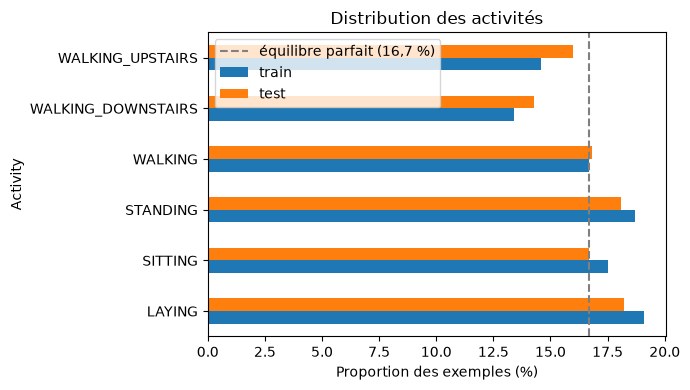

In [4]:
prop = pd.DataFrame({
    "train": train["Activity"].value_counts(normalize=True) * 100,
    "test": test["Activity"].value_counts(normalize=True) * 100,
}).round(1)
print(prop)

# Rapport entre la classe la plus fréquente et la plus rare (train)
effectifs = train["Activity"].value_counts()
print("Rapport max/min :", round(effectifs.max() / effectifs.min(), 2))

prop.plot(kind="barh", figsize=(7, 4))
plt.axvline(100 / 6, color="gray", linestyle="--", label="équilibre parfait (16,7 %)")
plt.xlabel("Proportion des exemples (%)")
plt.title("Distribution des activités")
plt.legend()
plt.tight_layout()
plt.show()

La classe la plus fréquente est LAYING (1407 fenêtres) et la plus rare WALKING_DOWNSTAIRS (986), soit un rapport de 1,4. Les classes sont plutôt équilibrées et leurs proportions sont proches entre le train et le test. L'accuracy ne sera donc pas trompeuse ici, mais je suivrai quand même le F1 par classe.

### 1.2.3 Statistiques descriptives (c)

Un `describe()` complet fait 561 colonnes et n'est pas lisible. Je calcule donc la moyenne, l'écart-type, le minimum et le maximum de chaque variable, puis je résume ces 4 statistiques sur l'ensemble des variables.

In [5]:
X_train = train.drop(columns=["subject", "Activity"])
stats = X_train.describe().T[["mean", "std", "min", "max"]]
print(stats.describe().round(3))

print()
print("Variables dont le min vaut -1 :", (stats["min"] == -1).sum())
print("Variables dont le max vaut 1  :", (stats["max"] == 1).sum())
print("Moyennes : de", round(stats["mean"].min(), 3), "à", round(stats["mean"].max(), 3))
print("Écarts-types : de", round(stats["std"].min(), 3), "à", round(stats["std"].max(), 3))

          mean      std      min      max
count  561.000  561.000  561.000  561.000
mean    -0.508    0.284   -0.990    0.978
std      0.428    0.137    0.050    0.069
min     -0.984    0.041   -1.000    0.465
25%     -0.868    0.192   -1.000    1.000
50%     -0.659    0.265   -1.000    1.000
75%     -0.108    0.362   -1.000    1.000
max      0.830    0.752   -0.494    1.000

Variables dont le min vaut -1 : 466
Variables dont le max vaut 1  : 452
Moyennes : de -0.984 à 0.83
Écarts-types : de 0.041 à 0.752


Je remarque que toutes les variables sont bornées dans [-1, 1] (466 atteignent -1 et 452 atteignent 1). Les auteurs ont donc fait une normalisation min-max. En revanche, les moyennes vont de -0,98 à 0,83 et les écarts-types de 0,04 à 0,75 : les variables ne sont pas standardisées.

### 1.2.4 Visualisations (d)

**1.2.4 (i) Histogrammes.** Je compare deux variables de nature différente : une moyenne et un écart-type du signal d'accélération du corps sur l'axe X.

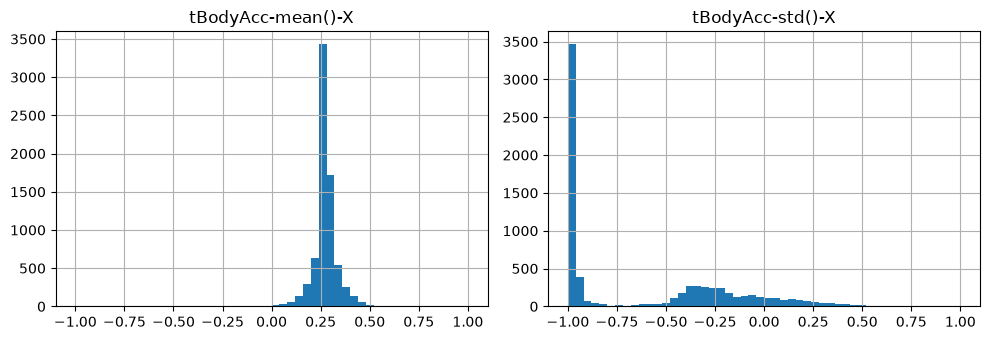

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for ax, col in zip(axes, ["tBodyAcc-mean()-X", "tBodyAcc-std()-X"]):
    X_train[col].hist(bins=50, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

La première variable a une seule bosse très serrée autour de 0,27 (quelques valeurs isolées à -1 et 1 étirent l'axe). La seconde est très différente : un énorme pic collé à -1 et une bosse plus étalée entre -0,5 et 0,5. Je suppose que le pic correspond aux activités immobiles et la bosse aux marches. Je le vérifie en colorant l'histogramme par activité.

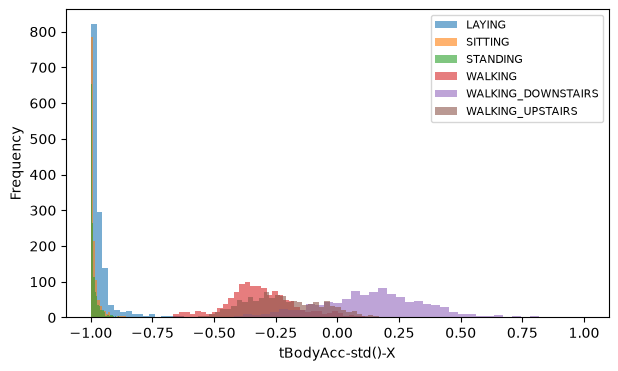

In [7]:
col = "tBodyAcc-std()-X"
plt.figure(figsize=(7, 4))
for activite, groupe in train.groupby("Activity"):
    groupe[col].plot(kind="hist", bins=40, alpha=0.6, label=activite)
plt.xlabel(col)
plt.legend(fontsize=8)
plt.show()

Je constate que les trois activités immobiles (SITTING, STANDING, LAYING) sont empilées autour de -1, alors que les trois marches s'en détachent, WALKING_DOWNSTAIRS étant la plus à droite. Cette variable sépare donc bien « immobile » et « en mouvement », mais elle ne distingue pas les trois activités immobiles entre elles.

**1.2.4 (ii) Boxplots.** Je compare 2 variables selon l'activité : un angle par rapport à la gravité, et l'écart-type de l'accélération.

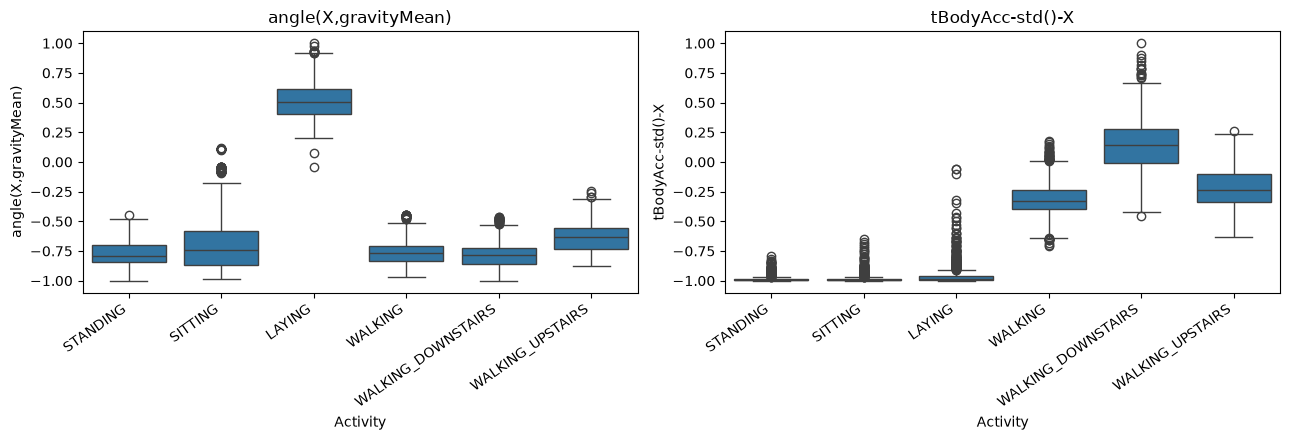

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, col in zip(axes, ["angle(X,gravityMean)", "tBodyAcc-std()-X"]):
    sns.boxplot(data=train, x="Activity", y=col, ax=ax)
    ax.set_title(col)
    plt.setp(ax.get_xticklabels(), rotation=35, ha="right")
plt.tight_layout()
plt.show()

Pour `angle(X,gravityMean)`, LAYING est loin au-dessus des autres (médiane de 0,51 contre -0,6 à -0,8) : quand le téléphone est couché, son angle avec la gravité change complètement. Pour `tBodyAcc-std()-X`, les trois activités immobiles ont des boîtes minuscules collées à -1 et les marches s'en détachent, mais WALKING et WALKING_UPSTAIRS se chevauchent en partie. Sur ces deux variables, SITTING et STANDING restent mélangées : je m'attends à ce que ce soit une paire difficile pour le modèle. Chaque variable ne raconte qu'une partie de l'histoire, ce qui justifie de les combiner dans un réseau.

**1.2.4 (iii) Corrélations.** Je calcule la matrice de corrélation des 561 variables. Je masque leurs noms, trop nombreux, et je compte les paires très corrélées.

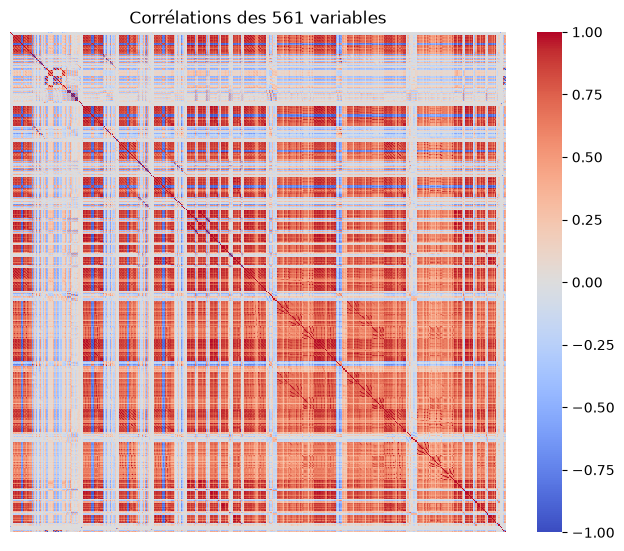

Nombre de paires de variables : 157080
Paires avec |r| > 0.9 : 8206 (5.2 %)


In [9]:
corr_all = X_train.corr()

plt.figure(figsize=(8, 6.5))
sns.heatmap(corr_all, cmap="coolwarm", center=0, vmin=-1, vmax=1,
            xticklabels=False, yticklabels=False)
plt.title("Corrélations des 561 variables")
plt.show()

# Chaque paire est comptée une seule fois (triangle supérieur de la matrice)
absc = corr_all.abs().to_numpy()
haut = absc[np.triu_indices_from(absc, k=1)]
print("Nombre de paires de variables :", len(haut))
print("Paires avec |r| > 0.9 :", (haut > 0.9).sum(), f"({(haut > 0.9).mean() * 100:.1f} %)")

Je vois de grands blocs rouges : ce sont des variables qui mesurent la même chose sous plusieurs formes (écart-type, MAD, IQR, énergie d'un même signal). Il y a aussi des bandes bleues (les minimums, anticorrélés avec ces mesures de dispersion) et des bandes grises (variables presque indépendantes, comme les moyennes). 8206 paires (5,2 %) ont une corrélation supérieure à 0,9 en valeur absolue : l'information est très redondante. Un MLP supporte bien cela, mais je le garde en tête.

### 1.2.5 Qualité des données

Pour décider du prétraitement, je cherche les valeurs manquantes, les doublons, les colonnes constantes, les valeurs hors de [-1, 1] et les valeurs extrêmes.

In [10]:
# Valeurs manquantes et lignes dupliquées
print("Valeurs manquantes  train :", train.isna().sum().sum(), "| test :", test.isna().sum().sum())
print("Lignes dupliquées   train :", train.duplicated().sum(), "| test :", test.duplicated().sum())

# Colonnes constantes et colonnes copies exactes d'une autre
print("Colonnes constantes :", (X_train.nunique() <= 1).sum())
colonnes_copies = X_train.T.duplicated()
print("Colonnes copies d'une autre :", colonnes_copies.sum())
print(list(X_train.columns[colonnes_copies.to_numpy()]))

# Valeurs hors de [-1, 1]
X_test = test.drop(columns=["subject", "Activity"])
print("Valeurs hors [-1,1] train :", (X_train.abs() > 1).sum().sum(),
      "| test :", (X_test.abs() > 1).sum().sum())

# Valeurs extrêmes : règle des boxplots (1,5 x IQR) puis z-score
Q1, Q3 = X_train.quantile(0.25), X_train.quantile(0.75)
IQR = Q3 - Q1
hors_moustaches = (X_train < Q1 - 1.5 * IQR) | (X_train > Q3 + 1.5 * IQR)
print("% de valeurs hors moustaches :", round(hors_moustaches.to_numpy().mean() * 100, 1))
Z = ((X_train - X_train.mean()) / X_train.std()).abs()
print("Valeurs avec |z| > 5  :", (Z > 5).sum().sum())
print("Valeurs avec |z| > 10 :", (Z > 10).sum().sum(), "| z maximal :", round(Z.max().max(), 1))

Valeurs manquantes  train : 0 | test : 0
Lignes dupliquées   train : 0 | test : 0
Colonnes constantes : 0


Colonnes copies d'une autre : 21
['tBodyAccMag-sma()', 'tGravityAccMag-mean()', 'tGravityAccMag-std()', 'tGravityAccMag-mad()', 'tGravityAccMag-max()', 'tGravityAccMag-min()', 'tGravityAccMag-sma()', 'tGravityAccMag-energy()', 'tGravityAccMag-iqr()', 'tGravityAccMag-entropy()', 'tGravityAccMag-arCoeff()1', 'tGravityAccMag-arCoeff()2', 'tGravityAccMag-arCoeff()3', 'tGravityAccMag-arCoeff()4', 'tBodyAccJerkMag-sma()', 'tBodyGyroMag-sma()', 'tBodyGyroJerkMag-sma()', 'fBodyAccMag-sma()', 'fBodyBodyAccJerkMag-sma()', 'fBodyBodyGyroMag-sma()', 'fBodyBodyGyroJerkMag-sma()']
Valeurs hors [-1,1] train : 0 | test : 0
% de valeurs hors moustaches : 4.0
Valeurs avec |z| > 5  : 7415
Valeurs avec |z| > 10 : 658 | z maximal : 34.2


Je constate que les données sont propres : pas de valeur manquante, de ligne dupliquée, de colonne constante ni de valeur hors de [-1, 1]. En revanche, 21 colonnes sont des copies exactes d'une autre. Par exemple, les `tGravityAccMag-*` sont identiques aux `tBodyAccMag-*`, et les `-sma()` des signaux de magnitude sont identiques aux `-mean()`.

Environ 4 % des valeurs sortent des moustaches des boxplots, mais je ne les considère pas comme aberrantes. Elles restent bornées dans [-1, 1] et viennent surtout des activités dynamiques (variables à deux bosses) : ce sont de vraies mesures, pas des erreurs de capteur.

### 1.2.6 Discussion et choix de prétraitement (e)

Je retire les 21 colonnes copies (repérées sur le train, puis la même liste est appliquée au test), et j'encode la cible en entiers.

In [11]:
colonnes_copies = set(X_train.columns[X_train.T.duplicated().to_numpy()])
feature_cols = [c for c in X_train.columns if c not in colonnes_copies]
print("Variables conservées :", len(feature_cols))

X_train = train[feature_cols]
X_test = test[feature_cols]
print(X_train.shape, X_test.shape)

# Encodage de la cible : un entier par activité (ordre alphabétique)
encoder = LabelEncoder()
y_train = encoder.fit_transform(train["Activity"])
y_test = encoder.transform(test["Activity"])
print({c: i for i, c in enumerate(encoder.classes_)})

Variables conservées : 540
(7352, 540) (2947, 540)
{'LAYING': 0, 'SITTING': 1, 'STANDING': 2, 'WALKING': 3, 'WALKING_DOWNSTAIRS': 4, 'WALKING_UPSTAIRS': 5}


**Réponses aux questions de l'énoncé et choix retenus**

- **Les variables sont-elles déjà mises à l'échelle ?** En partie. Elles sont toutes dans [-1, 1], mais leurs moyennes et écarts-types sont très différents. Je les standardiserai, avec une moyenne et un écart-type calculés sur l'entraînement seulement, pour éviter qu'une information de la validation ou du test ne passe dans l'entraînement. Je le fais en 1.3.3, une fois le découpage fait.
- **`subject` doit-il servir d'entrée ?** Non. C'est un identifiant et pas une mesure, et les volontaires du test sont absents du train. Le modèle risquerait d'apprendre à reconnaître des personnes plutôt que des mouvements. Je garde cette colonne seulement pour découper la validation par volontaire.
- **Suppression de colonnes :** je retire les 21 copies exactes, il reste 540 variables. Je garde les variables corrélées et les valeurs extrêmes (voir 1.2.4 et 1.2.5).
- **Encodage :** `Activity` devient un entier de 0 à 5, le format attendu par `CrossEntropyLoss`.

## 1.3 Découpage et ensemble de validation

> **Demandé :** le test ne sert qu'**une seule fois**, à la fin ; tous les choix (architecture, activation, optimiseur, pas d'apprentissage, régularisation, nombre d'époques) se font sur un ensemble de validation extrait de `train.csv`.
> - (a) Construire cet ensemble en réservant quelques volontaires entiers (4 ou 5), pas des lignes tirées au hasard, et expliquer pourquoi : deux fenêtres consécutives d'un même volontaire se chevauchent et se ressemblent beaucoup.
> - (b) Comparer, pour un même modèle, la performance de validation d'un découpage aléatoire et d'un découpage par volontaire. Lequel est le plus proche de la performance de test ? Conclure.

Mes étapes : 1.3.1 (explication de (a)), 1.3.2 (construction de (a)), 1.3.3 (standardisation), 1.3.4 (comparaison (b)) et 1.3.5 (conclusion).

### 1.3.1 Pourquoi découper par volontaire (a)

Les fenêtres durent 2,56 s et se chevauchent de moitié. Je mesure donc à quel point deux fenêtres consécutives se ressemblent (distance entre leurs 561 variables), et je compare avec deux fenêtres de personnes différentes qui font la même activité.

In [12]:
X_brut = train.drop(columns=["subject", "Activity"]).to_numpy()
sub = train["subject"].to_numpy()
act = train["Activity"].to_numpy()

# Paires de lignes consécutives, même volontaire et même activité
memes = (sub[1:] == sub[:-1]) & (act[1:] == act[:-1])
d_consecutives = np.linalg.norm(X_brut[1:] - X_brut[:-1], axis=1)[memes]

# Paires tirées au hasard : volontaires différents, même activité
rng = np.random.RandomState(SEED)
d_autres = []
while len(d_autres) < 5000:
    i, j = rng.randint(0, len(X_brut), 2)
    if sub[i] != sub[j] and act[i] == act[j]:
        d_autres.append(np.linalg.norm(X_brut[i] - X_brut[j]))

print("Distance médiane, lignes consécutives    :", round(np.median(d_consecutives), 2))
print("Distance médiane, volontaires différents :", round(np.median(d_autres), 2))

Distance médiane, lignes consécutives    : 3.37
Distance médiane, volontaires différents : 5.86


Je constate que deux fenêtres consécutives sont nettement plus proches (distance médiane de 3,4) que deux fenêtres de volontaires différents faisant la même activité (5,9). Avec un découpage aléatoire des lignes, une fenêtre de validation aurait presque toujours une voisine quasi identique dans l'entraînement : la validation mesurerait de la mémorisation. En réservant des volontaires entiers, je reproduis la situation du test, c'est-à-dire des personnes jamais vues.

### 1.3.2 Construction de l'entraînement et de la validation (a)

Je regarde d'abord combien de fenêtres chaque volontaire a pour chaque activité.

In [13]:
tableau = pd.crosstab(train["subject"], train["Activity"])
tableau.columns = [c.replace("WALKING_", "") if c != "WALKING" else c for c in tableau.columns]
tableau["Total"] = tableau.sum(axis=1)
tableau = tableau.rename_axis(index="Volontaire", columns=None)
tableau

,LAYING,SITTING,STANDING,WALKING,DOWNSTAIRS,UPSTAIRS,Total
Volontaire,,,,,,,
1,50,47,53,95,49,53,347
3,62,52,61,58,49,59,341
5,52,44,56,56,47,47,302
6,57,55,57,57,48,51,325
7,52,48,53,57,47,51,308
8,54,46,54,48,38,41,281
11,57,53,47,59,46,54,316
14,51,54,60,59,45,54,323
15,72,59,53,54,42,48,328


Chaque volontaire a fait les 6 activités (entre 281 et 409 fenêtres), donc les 6 classes seront présentes en validation, quels que soient les volontaires que je réserve.

Je tire 5 volontaires au hasard avec la graine fixée, puis je vérifie qu'aucun n'est commun aux deux ensembles et que les classes restent équilibrées.

In [14]:
volontaires = sorted(train["subject"].unique().tolist())
rng = np.random.RandomState(SEED)
vol_val = sorted(rng.choice(volontaires, size=5, replace=False).tolist())
print("Volontaires de validation :", vol_val)

masque_val = train["subject"].isin(vol_val)
tr_df = train[~masque_val]     # entraînement : les 16 autres volontaires
val_df = train[masque_val]     # validation : les 5 volontaires réservés

print("Entraînement :", tr_df.shape[0], "fenêtres,", tr_df["subject"].nunique(), "volontaires")
print("Validation   :", val_df.shape[0], "fenêtres,", val_df["subject"].nunique(), "volontaires")
print("Volontaires en commun :", set(tr_df["subject"]) & set(val_df["subject"]))

pd.DataFrame({
    "entraînement (%)": tr_df["Activity"].value_counts(normalize=True) * 100,
    "validation (%)": val_df["Activity"].value_counts(normalize=True) * 100,
}).round(1)

Volontaires de validation : [1, 3, 15, 25, 27]
Entraînement : 5551 fenêtres, 16 volontaires
Validation   : 1801 fenêtres, 5 volontaires
Volontaires en commun : set()


,entraînement (%),validation (%)
Activity,,
LAYING,19.4,18.4
SITTING,17.9,16.3
STANDING,19.0,17.8
WALKING,16.0,18.8
WALKING_DOWNSTAIRS,13.4,13.4
WALKING_UPSTAIRS,14.4,15.3


Le tirage donne les volontaires 1, 3, 15, 25 et 27. J'obtiens 5551 fenêtres d'entraînement (16 volontaires) et 1801 fenêtres de validation (5 volontaires), sans volontaire en commun. Les proportions de classes sont proches dans les deux ensembles (écart maximal de 2,8 points, pour WALKING), donc la validation est représentative.

### 1.3.3 Standardisation (suite du prétraitement de 1.2.6)

Je standardise les variables (moyenne 0, écart-type 1). Le `StandardScaler` est ajusté sur l'entraînement seulement, puis appliqué à la validation.

In [15]:
X_tr = tr_df[feature_cols].to_numpy()
X_val = val_df[feature_cols].to_numpy()
y_tr = encoder.transform(tr_df["Activity"])
y_val = encoder.transform(val_df["Activity"])

scaler = StandardScaler().fit(X_tr)
X_tr_s = scaler.transform(X_tr)
X_val_s = scaler.transform(X_val)

print("Entraînement : moyenne", round(X_tr_s.mean(), 3), "| écart-type moyen", round(X_tr_s.std(axis=0).mean(), 3))
print("Validation   : moyenne", round(X_val_s.mean(), 3), "| écart-type moyen", round(X_val_s.std(axis=0).mean(), 3))

Entraînement : moyenne -0.0 | écart-type moyen 1.0
Validation   : moyenne -0.049 | écart-type moyen 0.872


Sur l'entraînement, je retrouve bien une moyenne de 0 et un écart-type de 1. Sur la validation, je trouve une moyenne de -0,05 et un écart-type moyen de 0,87 : ce n'est pas exactement 0 et 1, et c'est normal puisque ses propres statistiques ne sont pas utilisées, comme ce sera le cas pour un nouveau volontaire. Les variables de ces 5 volontaires sont un peu moins dispersées que celles de l'entraînement.

### 1.3.4 Découpage aléatoire ou par volontaire (b)

Pour comparer les deux découpages, j'utilise une régression logistique multiclasse (c'est le modèle de référence, que j'analyse en détail en 1.4). Je l'entraîne d'abord sur le découpage par volontaire. Puis je la répète sur un découpage aléatoire des lignes, de même taille que la validation (1801 lignes), avec 5 graines différentes pour mesurer la variabilité.

In [16]:
# Découpage par volontaire (celui de 1.3.2)
logreg = LogisticRegression(max_iter=2000, random_state=SEED)
logreg.fit(X_tr_s, y_tr)
pred = logreg.predict(X_val_s)
acc_vol = accuracy_score(y_val, pred)
f1_vol = f1_score(y_val, pred, average="macro")

# Découpage aléatoire, 5 graines (standardisation recalculée à chaque fois sur l'entraînement)
n_val = len(val_df)
X_all = train[feature_cols].to_numpy()
y_all = encoder.transform(train["Activity"])

acc_alea, f1_alea = [], []
for graine in range(5):
    idx_tr, idx_val = train_test_split(np.arange(len(train)), test_size=n_val,
                                       random_state=graine, shuffle=True)
    sc = StandardScaler().fit(X_all[idx_tr])
    m = LogisticRegression(max_iter=2000, random_state=SEED)
    m.fit(sc.transform(X_all[idx_tr]), y_all[idx_tr])
    p = m.predict(sc.transform(X_all[idx_val]))
    acc_alea.append(accuracy_score(y_all[idx_val], p))
    f1_alea.append(f1_score(y_all[idx_val], p, average="macro"))

print(f"Découpage par volontaire : accuracy = {acc_vol:.4f} | F1 macro = {f1_vol:.4f}")
print(f"Découpage aléatoire      : accuracy = {np.mean(acc_alea):.4f} ± {np.std(acc_alea):.4f}"
      f" | F1 macro = {np.mean(f1_alea):.4f} ± {np.std(f1_alea):.4f}")

Découpage par volontaire : accuracy = 0.9589 | F1 macro = 0.9552
Découpage aléatoire      : accuracy = 0.9851 ± 0.0013 | F1 macro = 0.9863 ± 0.0011


Je constate que le découpage aléatoire donne 0,9851 ± 0,0013 d'accuracy, contre 0,9589 pour le découpage par volontaire. L'écart est d'environ 2,6 points, bien plus grand que la variabilité entre tirages (0,13 point), donc il est réel. Le découpage aléatoire surestime la performance, ce qui s'explique par les fenêtres quasi identiques présentes à la fois dans l'entraînement et la validation.

### 1.3.5 Conclusion de 1.3

**Ce que je peux conclure maintenant :** le découpage aléatoire est trop optimiste, donc je n'utiliserai que la validation par volontaire (volontaires 1, 3, 15, 25 et 27) pour mes choix.

**Ce que je ne peux pas encore conclure :** l'énoncé demande aussi lequel des deux découpages est le plus proche de la performance de test. Le test ne doit servir qu'une seule fois, donc je répondrai à cette question en 5.2, en même temps que l'évaluation finale. Autre limite : le découpage par volontaire ne repose que sur un seul tirage de 5 personnes.

## 1.4 Une référence simple

> **Demandé :** avant tout réseau de neurones, entraîner une régression logistique multiclasse (ou un réseau sans couche cachée). Ses performances servent de référence : chaque réseau devra être comparé à elle.

Le modèle `logreg` entraîné en 1.3.4 sur le découpage par volontaire est cette référence. Je regarde ici ses performances en détail : accuracy, F1 par classe et nombre de paramètres.

In [17]:
print("Accuracy entraînement :", round(logreg.score(X_tr_s, y_tr), 4))
print("Accuracy validation   :", round(acc_vol, 4), "| F1 macro :", round(f1_vol, 4))
print("Nombre de paramètres  :", logreg.coef_.size + logreg.intercept_.size)
print()
print(classification_report(y_val, pred, target_names=encoder.classes_, digits=3))

Accuracy entraînement : 0.9964
Accuracy validation   : 0.9589 | F1 macro : 0.9552
Nombre de paramètres  : 3246

                    precision    recall  f1-score   support

            LAYING      1.000     0.991     0.995       331
           SITTING      0.923     0.980     0.950       293
          STANDING      0.980     0.935     0.957       321
           WALKING      0.974     0.997     0.985       338
WALKING_DOWNSTAIRS      1.000     0.822     0.902       242
  WALKING_UPSTAIRS      0.887     1.000     0.940       276

          accuracy                          0.959      1801
         macro avg      0.961     0.954     0.955      1801
      weighted avg      0.962     0.959     0.958      1801



La référence atteint 0,9589 d'accuracy et 0,9552 de F1 macro en validation, avec 3246 paramètres (6 sorties × 541). La classe la plus difficile est WALKING_DOWNSTAIRS (F1 de 0,902, recall de 0,822). Comme WALKING_UPSTAIRS a un recall de 1,0 mais une precision de 0,887, je pense que des « descentes » sont prises pour des « montées ». La matrice de confusion le confirmera en 5.2. SITTING et STANDING sont aussi confondues (F1 de 0,950 et 0,957), mais moins que je ne le pensais.

Je constate aussi un écart entre l'entraînement (0,9964) et la validation (0,9589) : le modèle surapprend déjà, même sans couche cachée. Je regarderai si la régularisation (partie 4, dans la Version 2) réduit cet écart. Ces résultats sont à confirmer sur d'autres volontaires, car la validation n'en contient que 5.

# Partie 2 : Première architecture de réseau

> **Ce qui est demandé dans cette partie :** construire un réseau à une seule couche cachée (2.1), le comparer selon l'activation et l'optimiseur (2.2), puis mesurer la variabilité des résultats avec plusieurs graines (2.3).

## Préparation technique : DataLoaders

> Ce n'est pas une question de l'énoncé : la structure de code imposée en 8.1 (étape 3) demande de préparer les DataLoaders après le découpage. Je le fais ici, juste avant d'en avoir besoin pour le premier réseau.

*À compléter : tenseurs et DataLoaders à partir de `X_tr_s`, `y_tr`, `X_val_s` et `y_val`.*

## 2.1 Construction du réseau

> **Demandé :** un réseau avec une seule couche cachée (par exemple 64 neurones), une activation au choix parmi ReLU, Sigmoid, Tanh, et une perte adaptée à la classification multiclasse (par exemple `CrossEntropyLoss`). Avant d'entraîner, vérifier la perte initiale (quelle valeur attend-on ?) et contrôler que le réseau sait surapprendre un petit lot de données.

*À compléter.*

## 2.2 Essais : activations, optimiseurs, métriques

> **Demandé :** faire varier la fonction d'activation ; tester SGD, SGD avec momentum et Adam, avec un pas d'apprentissage réglé pour chacun (LR range test ou petite grille logarithmique) ; suivre accuracy et loss en entraînement et en validation à chaque époque ; réfléchir à l'accuracy contre le F1-score (macro et par classe) ; commenter la convergence, la stabilité, le sous-apprentissage et le surapprentissage.

*À compléter.*

## 2.3 Variabilité des résultats

> **Demandé :** pour au moins deux configurations, répéter l'entraînement avec au moins 3 graines et donner la moyenne et l'écart-type des scores. Un écart entre deux configurations plus petit que cette variabilité ne permet pas de conclure. Appliquer ce principe à toutes les comparaisons importantes.

*À compléter.*

# Partie 3 : Extension de l'architecture

> **Ce qui est demandé dans cette partie :** augmenter la taille de la couche cachée (3.1), puis tester des réseaux plus profonds (3.2, dans le notebook Version 2).

## 3.1 Taille de la couche cachée

> **Demandé :** augmenter progressivement la taille de la couche cachée (par exemple 128, 256 neurones), analyser l'impact sur les performances et sur le surapprentissage, et indiquer le nombre de paramètres de chaque modèle.

*À compléter.*

# Partie 5 : Visualisation et analyse des performances

> **Ce qui est demandé dans cette partie :** tracer les courbes d'apprentissage (5.1), puis évaluer une seule fois sur le test les configurations retenues et la référence de 1.4, avec la matrice de confusion (5.2).

## 5.1 Courbes d'apprentissage

> **Demandé :** tracer l'évolution de la loss et de l'accuracy (ou du F1-score), en entraînement et en validation, au cours des époques, pour suivre la convergence et détecter un surapprentissage ou un sous-apprentissage.

*À compléter.*

## 5.2 Évaluation finale et matrice de confusion

> **Demandé :** évaluer **une seule fois** sur le test les 2 ou 3 configurations retenues ainsi que la référence de 1.4, et comparer ces scores à ceux de la validation. Calculer et visualiser la matrice de confusion sur le test, commenter les classes les plus difficiles à prédire, et dire si les confusions sont plausibles du point de vue des capteurs.
>
> **À faire ici aussi :** répondre à la question laissée ouverte en 1.3 (b) : entre le découpage aléatoire et le découpage par volontaire, lequel donne une validation plus proche du score de test de la régression logistique ?

*À compléter.*